In [1]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU disponibile:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    x = torch.ones(4, device="cuda")
    print("Test di calcolo:", (x * 2).cpu().tolist())

Python: 3.13.15
PyTorch: 2.11.0+cu128
GPU disponibile: True
GPU: Tesla T4
Test di calcolo: [2.0, 2.0, 2.0, 2.0]


In [1]:
%pip install anomalib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 7.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 15.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.9/803.9 kB 17.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 90.7 MB/s  0:00:00m eta 0:00:01
  Created wheel for freia: filename=freia-0.2-py3-none-any.whl size=42849 sha256=0c3eabe0b343a3ed847af912f29d5512f3757ef7b6b90f63e5a1f0269de76937
  Stored in directory: /root/.cache/pip/wheels/b1/66/ba/29fd62b92bba7c42af99ae475baafa7d205b2c3e7fcc8670b7
Successfully built freia
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [anomalib]6/7 [anomalib]]s]]
Note: you may need to restart the kernel to use updated packages.


In [2]:
from importlib.metadata import version
from anomalib.models import Patchcore
from anomalib.engine import Engine

print("Anomalib:", version("anomalib"))
print("Import riusciti")

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Anomalib: 2.7.0
Import riusciti


In [1]:
from pathlib import Path

root = Path("/kaggle/input")

print("Contenuto di /kaggle/input:")
for path in root.iterdir():
    print(path)

print("\nJSON disponibili per PCB:")
for path in root.rglob("pcb.json"):
    print(path)

print("\nEsempio di immagine:")
print(next(root.rglob("*.jpg"), "Nessuna immagine JPG trovata"))

Contenuto di /kaggle/input:
/kaggle/input/datasets

JSON disponibili per PCB:
/kaggle/input/datasets/valeriovirgili/argus-realiad-pcb/realiad_jsons/realiad_jsons/pcb.json
/kaggle/input/datasets/valeriovirgili/argus-realiad-pcb/realiad_jsons/realiad_jsons_fuiad_0.0/pcb.json
/kaggle/input/datasets/valeriovirgili/argus-realiad-pcb/realiad_jsons/realiad_jsons_fuiad_0.1/pcb.json
/kaggle/input/datasets/valeriovirgili/argus-realiad-pcb/realiad_jsons/realiad_jsons_fuiad_0.2/pcb.json
/kaggle/input/datasets/valeriovirgili/argus-realiad-pcb/realiad_jsons/realiad_jsons_fuiad_0.4/pcb.json
/kaggle/input/datasets/valeriovirgili/argus-realiad-pcb/realiad_jsons/realiad_jsons_sv/pcb.json

Esempio di immagine:
/kaggle/input/datasets/valeriovirgili/argus-realiad-pcb/pcb/pcb/OK/S0001/pcb_0001_OK_C1_20231027155851.jpg


Immagini train: 1235
Immagini test: 3775
Percorso: /kaggle/input/datasets/valeriovirgili/argus-realiad-pcb/pcb/pcb/OK/S0004/pcb_0004_OK_C1_20231027155941.jpg
Dimensioni: (512, 512)


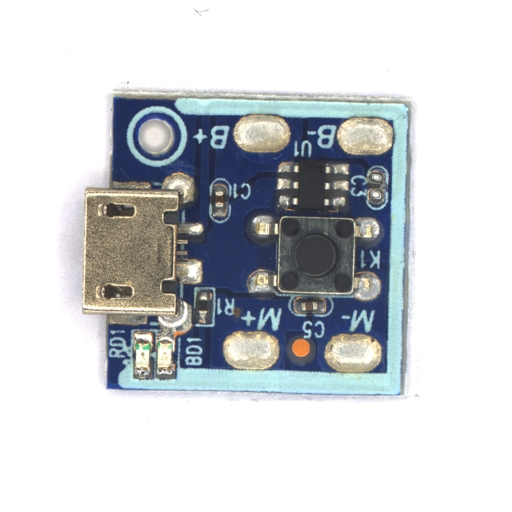

In [2]:
import json
from pathlib import Path
from PIL import Image
from IPython.display import display

BASE = Path("/kaggle/input/datasets/valeriovirgili/argus-realiad-pcb")
JSON_PATH = BASE / "realiad_jsons/realiad_jsons/pcb.json"

with JSON_PATH.open() as file:
    splits = json.load(file)

print("Immagini train:", len(splits["train"]))
print("Immagini test:", len(splits["test"]))

sample = splits["train"][0]
matches = list(BASE.rglob(Path(sample["image_path"]).name))

assert len(matches) == 1, f"Immagini trovate per il campione: {len(matches)}"

image = Image.open(matches[0])
print("Percorso:", matches[0])
print("Dimensioni:", image.size)
display(image)